# Sampling, Aliasing and Sensor Data Integrity Simulator

## Objective
Demonstrate sampling theory, aliasing, anti-alias filtering and missing-sample detection using reproducible synthetic signals.

## Experiments
1. Compare sampling rates for a 10 Hz sinusoid.
2. Demonstrate aliasing using a 70 Hz component.
3. Compare frequency spectra at different sampling rates.
4. Simulate analog anti-alias filtering before an ADC.
5. Detect missing samples using explicit sample indices.

## Tools
Python, NumPy, SciPy and Matplotlib.

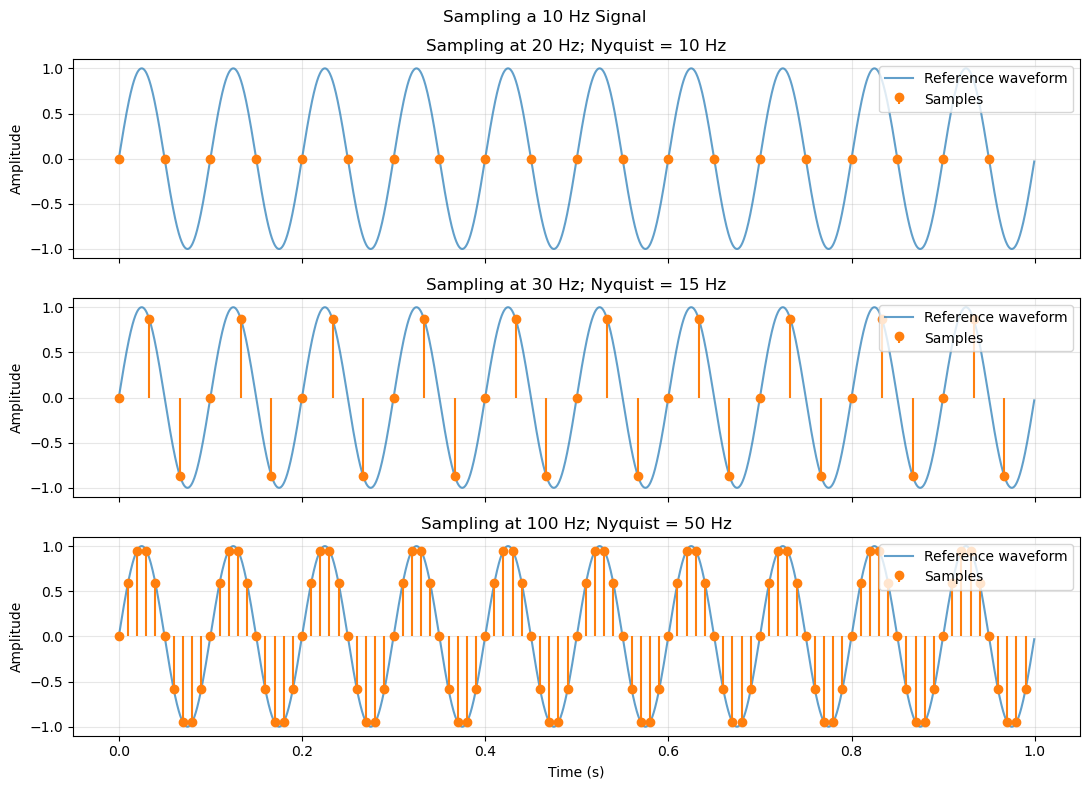

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Original signal: 10 Hz sinusoid
f_signal = 10
duration = 1.0

# High-rate reference used to visualize the waveform
fs_reference = 2000
t_reference = np.arange(
    0, duration, 1/fs_reference
)
x_reference = np.sin(
    2 * np.pi * f_signal * t_reference
)

# Compare three sampling rates
sampling_rates = [20, 30, 100]

fig, axes = plt.subplots(
    len(sampling_rates), 1,
    figsize=(11, 8), sharex=True
)

for ax, fs in zip(axes, sampling_rates):
    t_sampled = np.arange(0, duration, 1/fs)
    x_sampled = np.sin(
        2 * np.pi * f_signal * t_sampled
    )

    ax.plot(
        t_reference, x_reference,
        label="Reference waveform", alpha=0.7
    )
    ax.stem(
        t_sampled, x_sampled,
        linefmt="C1-", markerfmt="C1o",
        basefmt=" ", label="Samples"
    )

    ax.set_title(
        f"Sampling at {fs} Hz; Nyquist = {fs/2:g} Hz"
    )
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Sampling a 10 Hz Signal")
fig.tight_layout()
plt.savefig(
    "../outputs/plots/sampling_rates.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

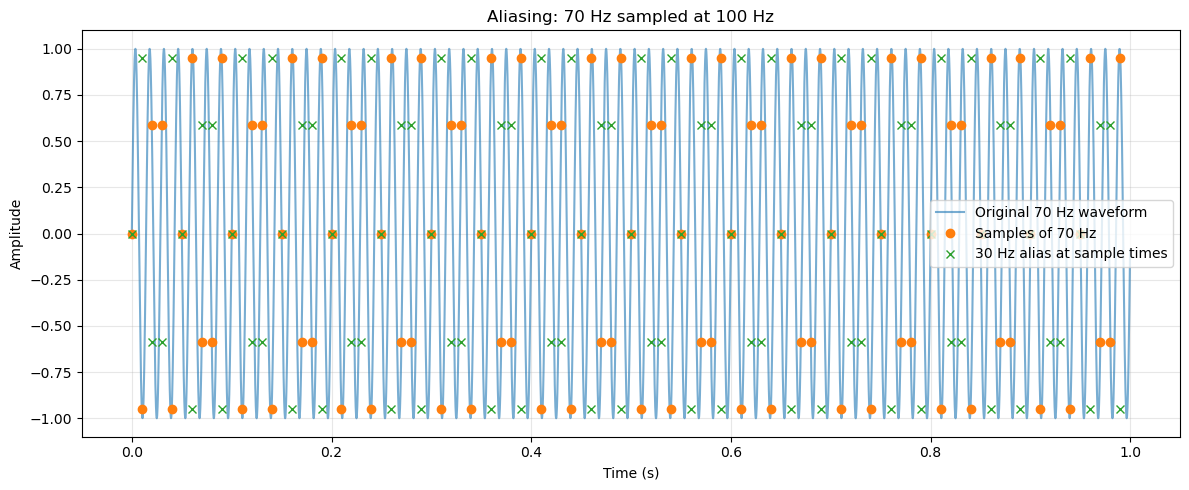

Sampling frequency: 100 Hz
Nyquist frequency: 50.0 Hz
Original frequency: 70 Hz
Expected alias frequency: 30 Hz


In [3]:
import numpy as np
import matplotlib.pyplot as plt

FS = 100
DURATION = 1.0

# High-rate reference
fs_reference = 5000
t_ref = np.arange(0, DURATION, 1/fs_reference)

f_original = 70
x_ref = np.sin(2*np.pi*f_original*t_ref)

# Sample at 100 Hz
t_sampled = np.arange(0, DURATION, 1/FS)
x_sampled = np.sin(2*np.pi*f_original*t_sampled)

# Expected alias frequency
f_alias = abs(f_original - round(f_original/FS)*FS)

# Show the sampled values against the alias waveform
x_alias = np.sin(2*np.pi*f_alias*t_sampled)

plt.figure(figsize=(12, 5))
plt.plot(t_ref, x_ref, label="Original 70 Hz waveform", alpha=0.6)
plt.plot(t_sampled, x_sampled, "o", label="Samples of 70 Hz")
plt.plot(t_sampled, x_alias, "x", label="30 Hz alias at sample times")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Aliasing: 70 Hz sampled at 100 Hz")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/plots/aliasing_70hz.png",
            dpi=200, bbox_inches="tight")
plt.show()

print("Sampling frequency:", FS, "Hz")
print("Nyquist frequency:", FS/2, "Hz")
print("Original frequency:", f_original, "Hz")
print("Expected alias frequency:", f_alias, "Hz")

## Experiment 2 — Aliasing Demonstration

A 70 Hz sinusoid was sampled at 100 Hz. The Nyquist frequency was 50 Hz, so the original signal exceeded the Nyquist limit.

The expected alias frequency was 30 Hz. The sampled values of the 70 Hz sinusoid coincide with those of a 30 Hz sinusoid at the sampling instants. Therefore, the original frequency cannot be uniquely identified from these samples alone without additional assumptions.

This experiment demonstrates why analog anti-alias filtering is needed before an ADC. Once out-of-band content has aliased into the sampled signal, digital filtering cannot generally distinguish it from genuine in-band content.

The result was obtained using a synthetic signal with a known original frequency. It demonstrates sampling theory rather than measuring a physical sensor.

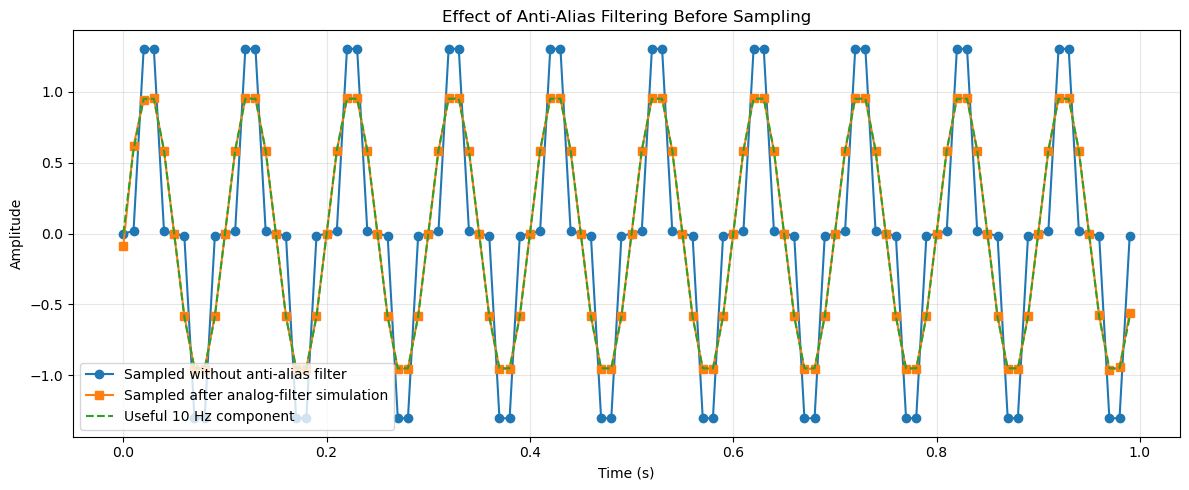

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

FS_ADC = 100
FS_ANALOG = 5000
DURATION = 1.0

t_analog = np.arange(0, DURATION, 1/FS_ANALOG)

useful = np.sin(2*np.pi*10*t_analog)
interference = 0.6*np.sin(2*np.pi*70*t_analog)
x_analog = useful + interference

# Simulate an analog anti-alias low-pass filter
sos = butter(
    4, 40, btype="lowpass",
    fs=FS_ANALOG, output="sos"
)
x_filtered = sosfiltfilt(sos, x_analog)

# Sample both signals at the ADC rate
step = FS_ANALOG // FS_ADC
t_adc = t_analog[::step]
x_unfiltered_adc = x_analog[::step]
x_filtered_adc = x_filtered[::step]

plt.figure(figsize=(12, 5))
plt.plot(t_adc, x_unfiltered_adc, "o-",
         label="Sampled without anti-alias filter")
plt.plot(t_adc, x_filtered_adc, "s-",
         label="Sampled after analog-filter simulation")
plt.plot(t_adc, np.sin(2*np.pi*10*t_adc), "--",
         label="Useful 10 Hz component")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Effect of Anti-Alias Filtering Before Sampling")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/plots/anti_alias_filter.png",
            dpi=200, bbox_inches="tight")
plt.show()

## Experiment 3 — Anti-Alias Filtering

A synthetic signal containing a useful 10 Hz component and unwanted 70 Hz interference was sampled at 100 Hz. Since the ADC's Nyquist frequency was 50 Hz, the 70 Hz component could alias into the sampled signal.

A fourth-order Butterworth low-pass filter with a 40 Hz cutoff was applied to the high-rate simulated input before downsampling. The filtered samples were closer to the useful 10 Hz waveform than the unfiltered samples.

The experiment illustrates the purpose of analog anti-alias filtering before an ADC. The simulated filter attenuates out-of-band interference but does not eliminate it completely. Actual hardware design requires consideration of the filter's transition band, attenuation, component tolerances and ADC requirements.

The filter was simulated digitally at a higher sampling rate; this experiment does not constitute a measurement of a physical analog circuit.

Expected samples: 2000
Observed samples: 1800
Missing samples: 200
Missing interval: 4.00 s to 5.00 s


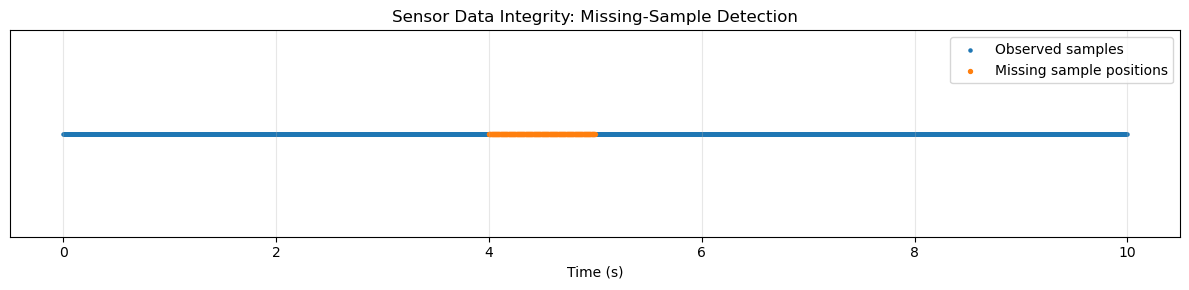

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FS = 200
DURATION = 10

# Expected sample indices
expected = np.arange(FS * DURATION)

# Simulate a one-second gap from 4 s to 5 s
missing_start = 4 * FS
missing_end = 5 * FS

observed = np.concatenate([
    expected[:missing_start],
    expected[missing_end:]
])

missing = np.setdiff1d(expected, observed)

print("Expected samples:", len(expected))
print("Observed samples:", len(observed))
print("Missing samples:", len(missing))

if len(missing):
    print(
        "Missing interval:",
        f"{missing[0]/FS:.2f} s to {(missing[-1]+1)/FS:.2f} s"
    )

plt.figure(figsize=(12, 3))
plt.scatter(observed / FS, np.ones(len(observed)),
            s=5, label="Observed samples")
plt.scatter(missing / FS, np.ones(len(missing)),
            s=8, label="Missing sample positions")
plt.xlabel("Time (s)")
plt.yticks([])
plt.title("Sensor Data Integrity: Missing-Sample Detection")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("../outputs/plots/missing_samples.png",
            dpi=200, bbox_inches="tight")
plt.show()